# Interactive demo: greedy algorithm for constructing an oriented hierarchy

This notebook runs the code of the repository directly in your browser.
It compares two algorithms on a random implication matrix:

- **SG**: classes selected by the Gras algorithm (`gras_algorithm`)
- **SN**: classes selected by the greedy merge algorithm (`greedy_algorithm`, threshold `alpha`)

Run the cells from top to bottom (menu *Runtime → Run all* on Colab).

In [1]:
# Setup: get the repository code if the notebook is opened outside the repo (e.g. on Colab)
import os, subprocess

REPO = "Study-of-the-greedy-algorithm-for-constructing-an-oriented-hierarchy"
URL = "https://github.com/Fidy-Heritiana/" + REPO + ".git"

if not os.path.exists("core_algorithms.py"):
    subprocess.run(["git", "clone", URL], check=True)
    os.chdir(REPO)

print("Repository code ready.")

Repository code ready.


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from core_algorithms import (
    generate_implication_matrix,
    gras_algorithm,
    greedy_algorithm,
    jaccard_dissimilarity,
    directional_distances,
)


def compare(n, alpha, seed):
    """Draw one random matrix and run both algorithms on it."""
    rng = np.random.default_rng(seed)
    M = generate_implication_matrix(n, rng)

    SG, _, active_g = gras_algorithm(M)
    SN, _, active_n, R_top2, _, R_strong, _, _ = greedy_algorithm(M, alpha=alpha)

    return {
        "M": M,
        "SG": SG,
        "SN": SN,
        "active_g": active_g,
        "active_n": active_n,
        "R_top2": R_top2,
        "R_strong": R_strong,
    }


def plot_chain_lengths(res):
    """Distribution of the final chain lengths for both algorithms."""
    len_g = [len(c) for c in res["active_g"]]
    len_n = [len(c) for c in res["active_n"]]
    top = max(len_g + len_n)
    bins = np.arange(1, top + 2) - 0.5

    plt.figure(figsize=(6, 3.5))
    plt.hist([len_g, len_n], bins=bins, label=["Gras", "greedy"])
    plt.xlabel("length of final chains")
    plt.ylabel("number of chains")
    plt.title("Final chains")
    plt.legend()
    plt.show()

## 1. One run

Change `n` (number of variables), `alpha` (threshold of the greedy algorithm) and `seed`, then run the cell.

|SG| = 11 classes   |SN| = 13 classes
Jaccard dissimilarity D_J(SG, SN) = 0.667
Directional distances: {'D_G': 0.45454545454545453, 'D_N': 0.5384615384615384, 'recall_G': 0.5454545454545454, 'precision_N': 0.46153846153846156, 'SG_subset_SN': False}
Violations: R_top2 = 9, R_strong = 12

Final chains (Gras):   [(1, 8, 14), (7, 3, 13), (5, 2, 11, 4), (12, 6, 9, 10, 0)]
Final chains (greedy): [(5, 2, 14, 1, 8, 12, 6), (7, 3, 13, 10, 11, 4, 9, 0)]


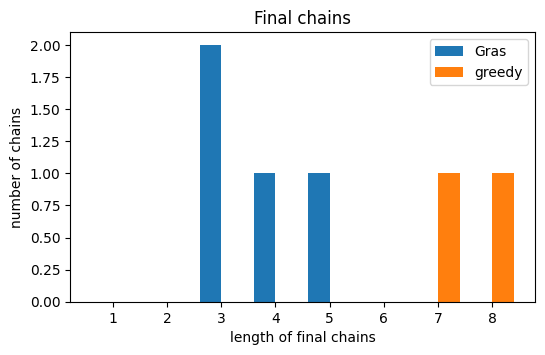

In [3]:
n, alpha, seed = 15, 0.7, 1

res = compare(n, alpha, seed)
SG, SN = res["SG"], res["SN"]

print(f"|SG| = {len(SG)} classes   |SN| = {len(SN)} classes")
print(f"Jaccard dissimilarity D_J(SG, SN) = {jaccard_dissimilarity(SG, SN):.3f}")
print("Directional distances:", directional_distances(SG, SN))
print(f"Violations: R_top2 = {res['R_top2']}, R_strong = {res['R_strong']}")
print()
print("Final chains (Gras):  ", res["active_g"])
print("Final chains (greedy):", res["active_n"])

plot_chain_lengths(res)

## 2. Sensitivity to alpha

Mean Jaccard dissimilarity between SG and SN over several random matrices, for different values of `alpha`.

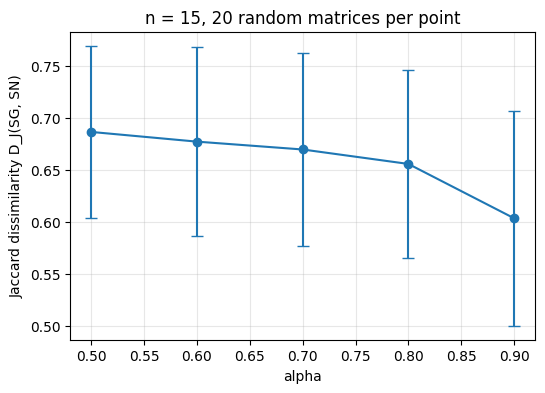

In [4]:
n, reps = 15, 20
alphas = [0.5, 0.6, 0.7, 0.8, 0.9]

means, stds = [], []
for a in alphas:
    d = [
        jaccard_dissimilarity(r["SG"], r["SN"])
        for r in (compare(n, a, s) for s in range(reps))
    ]
    means.append(np.mean(d))
    stds.append(np.std(d))

plt.figure(figsize=(6, 4))
plt.errorbar(alphas, means, yerr=stds, marker="o", capsize=4)
plt.xlabel("alpha")
plt.ylabel("Jaccard dissimilarity D_J(SG, SN)")
plt.title(f"n = {n}, {reps} random matrices per point")
plt.grid(alpha=0.3)
plt.show()

## 3. Interactive version

Move the sliders to see the result update. Sliders do not display in the GitHub preview: open this notebook on Colab or Binder to use them.

In [5]:
def run_demo(n=15, alpha=0.7, seed=1):
    res = compare(n, alpha, seed)
    SG, SN = res["SG"], res["SN"]

    print(f"|SG| = {len(SG)}   |SN| = {len(SN)}   "
          f"D_J = {jaccard_dissimilarity(SG, SN):.3f}   "
          f"R_top2 = {res['R_top2']}   R_strong = {res['R_strong']}")
    plot_chain_lengths(res)


try:
    from ipywidgets import interact, IntSlider, FloatSlider
    interact(
        run_demo,
        n=IntSlider(min=5, max=30, step=1, value=15),
        alpha=FloatSlider(min=0.5, max=0.95, step=0.05, value=0.7),
        seed=IntSlider(min=0, max=100, step=1, value=1),
    )
except ImportError:
    run_demo()

interactive(children=(IntSlider(value=15, description='n', max=30, min=5), FloatSlider(value=0.7, description=…